In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import beta

# 3 - Simulated Bayesian Inverse Problem
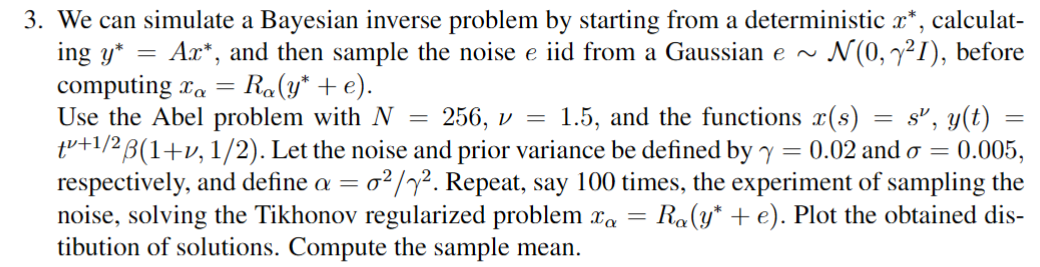

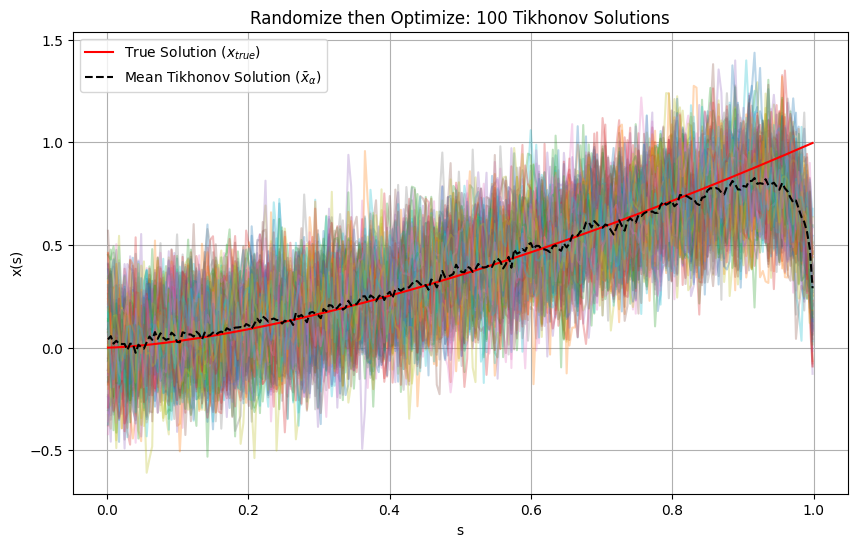

In [40]:
x_star = 0.5

# Set number of discretization points
N = 256
h = 1 / N  # grid spacing

# Exact solutions
nu = 1.5
x = lambda s: s**nu
y = lambda t: t**(nu+1/2)*beta(1+nu,1/2)

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

xvec = x(svec)
xvec= xvec.reshape(-1,1)
yvec = y(tvec)

gamma = 0.02
sigma = 0.005
alpha = sigma**2 / gamma**2

fig1, ax1 = plt.subplots(figsize=(10, 6))
K = 100
xalpha = np.zeros((N, K))
for k in range(K):
    noise = np.random.normal(0, scale=np.sqrt(gamma), size=(N, 1))
    relative_noise_level = np.linalg.norm(noise) / np.linalg.norm(yvec)
    yvecnoise = yvec + noise
    # print(yvecnoise.shape)

    yext = np.concatenate([yvecnoise, np.zeros((N, 1))], axis=0)
    # print(f"{yext.shape=}")
    Aalpha = np.vstack([A, np.sqrt(alpha) * np.eye(N)])
    # print(f"{Aalpha.shape=}")
    xalpha[:, k] = np.linalg.lstsq(Aalpha, yext, rcond=None)[0][:, 0]

    ax1.plot(svec, xalpha[:, k], alpha=0.3)

ax1.plot(svec, xvec, 'r-', markersize=5, label='True Solution ($x_{true}$)')
ax1.plot(svec, np.mean(xalpha, axis=1), 'k--', markersize=5, label='Mean Tikhonov Solution ($\\bar{x}_\\alpha$)')
ax1.set_title(f'Randomize then Optimize: {K} Tikhonov Solutions')
ax1.set_xlabel('s')
ax1.set_ylabel('x(s)')
ax1.legend()
ax1.grid(True)